<a href="https://colab.research.google.com/github/joey2846/Group-Project/blob/main/notebooks/member_a_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Team Members:
ZHU ZHENTAO - A206174

BIAN CHUNBO - A206292

HOU ZHENGYANG - A206407

---


## 1. Scenario
An online retailer wants to monitor customer satisfaction across its products using customer reviews. This dataset is suitable because it intentionally contains real-world data-quality issues—missing values scattered across nearly every column, duplicate listings, inconsistent currency and discount formats, and invalid ratings—that must be diagnosed and handled before any satisfaction analysis can be trusted. The retailer wants to know which products receive the most negative feedback and how potential quality issues can be flagged early.

## 2. Data Source(Member A)
**Source**: Kaggle

**Dataset Name**: Amazon products reviews dataset uncleaned

**Author**: Satyaki Das

**URL**: https://www.kaggle.com/datasets/satyakidas07/amazon-products-reviews-dataset-uncleaned

**Method**: Downloaded the `.xlsx` file directly from Kaggle and uploaded it to Google Colab. The data is loaded using `pandas.read_excel()`.

In [18]:
import pandas as pd
import numpy as np
import os


file_name = "Amazon_Products_Reviews_Dataset_UNCLEANED.xlsx"

if not os.path.exists(file_name):
    print("Downloading dataset from Kaggle. Please wait a moment...")

    import kagglehub

    path = kagglehub.dataset_download("satyakidas07/amazon-products-reviews-dataset-uncleaned")


    for root, dirs, files in os.walk(path):
        for file in files:
            if file.endswith(".xlsx"):
                file_name = os.path.join(root, file)
                break


df = pd.read_excel(file_name, sheet_name="Amazon_Data_Raw")
print("Data loaded successfully!")
df.head()

Using Colab cache for faster access to the 'amazon-products-reviews-dataset-uncleaned' dataset.
Data loaded successfully!


,product_id,product_name,category,Discounted_Price (INR),actual_price,discount_percentage,rating,Rating Count,about_product,user_id,user_name,review_id,review_title,review_content,IMG_LINK,product_link
0,B08SMJT55F,boAt Stone 250 Portable Wireless Speaker with ...,Electronics|HomeAudio|Speakers|BluetoothSpeakers,"₹1,199","₹3,990",70%,4.2,"2,908",Power- Get ready to be enthralled by the 5W RM...,"AHL435VQHZZXB545DXGLIZSACFOQ,AG6OEN75DD6ADCNOY...","Devashish Gautam,Vishakha,Sunny Tanna,Dr.Suman...","RLXE2MCKLCYMB,R39DFUZXNDFQ4,R30U7W2G83AI48,R2X...","Strudy, Awesome connectivity........but bass i...",The LED light is vibrant with multiple form se...,https://m.media-amazon.com/images/I/51J45Dcgkt...,https://www.amazon.in/boAt-Stone-250-Playback-...
1,B07F6GXNPB,EUREKA FORBES EUROCLEAN PAPER VACUUM CLEANER D...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cl...",₹253,₹500,49%,4.3,"2,664",Special Anti-Microbial(Biocide Treated) Paper ...,"AEAHCVLMYLKLICSIKCTUS54NVQ2A,AFRIWQJKFSDZKTRTU...","Lulzdrone,KRISH,Harsh Shah,Harsh,HaPa,Inderjee...","R2K8VZSTF6Y1UH,R30LKPXEPE0CZE,R2714DP5UNSOQ,R1...","Bigger size,Superb.,Vacuum Bag,Price is reason...",These are the biggest one their models use and...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Euroclean-...
2,B08TTRVWKY,MILTON Smart Egg Boiler 360-Watts (Transparent...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹1,099","₹1,899",42%,4.3,"1,811",3 Boiling Modes - The advanced appliance from ...,"AH2NLR3ZG7SADP6RTRU5PDZUBKYQ,AEDHYDNNCKCAOWK4...","Tapan Dutta,Seerat Dar,Saravana Kumar K N,Prad...","R1SPFVN2778DYH,R2GUT54B310MIN,R2WBP8YTLS3OPJ,R...","Nice good,Easy to use,Good , however little co...","Like it,Awesome product 😊,Follow the instructi...",https://m.media-amazon.com/images/I/41yrqUum9E...,https://www.amazon.in/MILTON-Smart-Egg-Boiler-...
3,B01MQ2A86A,"Logitech M331 Silent Plus Wireless Mouse, 2.4G...",Computers&Accessories|Accessories&Peripherals|...,NaN,"₹1,645",21%,4.6,"12,375",Quieter Click: Logitech’s SilentTouch Technolo...,"AE6TTPY5R4YW3XHTPGX6CGHLMVGA,AG5CBSM4UJ7KPPFIQ...","Awesome Shopper,Suresh madaka,Amazon Customer,...","R17S7JVWFH1X6W,R1HINIS5AG6PXD,R3VZFLZVFVZ13G,R...","Good but the scroll is now damaged,Nice,Noisel...",- excellent piece of wireless mouse- reasonabl...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Logitech-Silent-Wireless...
4,B08GM5S4CQ,Havells Instanio 10 Litre Storage Water Heater...,NaN,"₹6,990","₹14,290",51%,4.4,"1,771",Suitable for high-rise buildings and pressure ...,"AGUM6DLWGQ2LOM4MCKXEXKBXHXCQ,AELFZZK6GYFN3YA6T...","Amazon Customer,Gaurav,khalil shaikh,Aman Seti...","R3N1KWPD82KCJH,RUP7RE9R1GMG7,R1EM1ELIZK4UQO,R1...",Good product but attention needed in packing a...,"For this price range product design, look, spe...",https://m.media-amazon.com/images/I/31-XtyZy0I...,https://www.amazon.in/Havells-Instanio-Storage...


In [19]:

missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_pct.round(2)
})


missing_table[missing_table["Missing Count"] > 0].sort_values("Missing Percentage (%)", ascending=False)

,Missing Count,Missing Percentage (%)
Rating Count,27,1.81
rating,25,1.67
Discounted_Price (INR),22,1.47
category,22,1.47
discount_percentage,22,1.47
actual_price,22,1.47
about_product,22,1.47
product_name,19,1.27
IMG_LINK,19,1.27
product_link,19,1.27


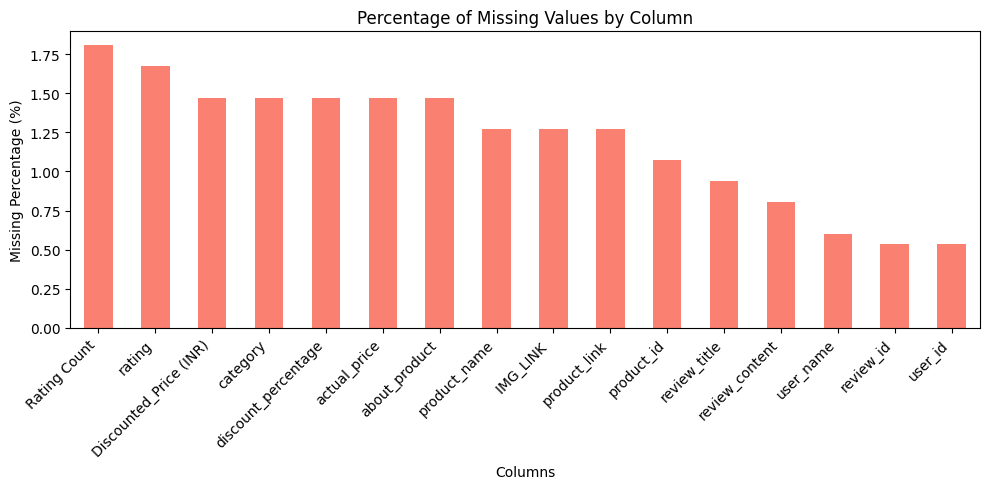

In [20]:
import matplotlib.pyplot as plt

missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_pct.plot(kind='bar', color='salmon')
plt.title('Percentage of Missing Values by Column')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Columns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Missing Values Analysis
The missing-value table shows that columns such as `review_title` and `review_content` contain missing values. This may occur when review text is unavailable, although the dataset does not specify the exact reasons.

Missing values in `user_name` may be related to anonymous reviews or incomplete user information.

Missing values in `rating` and `discount_percentage` may result from incomplete product records or data collection issues. These are possible explanations rather than confirmed causes.

In [21]:
import pandas as pd
import numpy as np

# Clean column names
df.columns = df.columns.str.strip()

# Find the rating column
rating_cols = [
    col for col in df.columns
    if 'rating' in col.lower() or 'score' in col.lower()
]

if rating_cols:
    target_col = 'rating' if 'rating' in df.columns else rating_cols[0]
    print(f"Found rating column: '{target_col}'")

    # Remove rows with missing ratings
    df_cleaned = df.dropna(subset=[target_col]).copy()

    # Fill missing review text
    text_cols = [
        col for col in df_cleaned.columns
        if "review" in col.lower() or "title" in col.lower()
    ]

    for col in text_cols:
        df_cleaned[col] = df_cleaned[col].fillna("No text provided")

    print("Review text processing complete!")

else:
    raise ValueError("No rating or score column was found.")


# Convert Rating Count to numeric values
def convert_rating_count(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().replace(",", "").upper()

    try:
        if value.endswith("K"):
            return float(value[:-1]) * 1000

        elif value.endswith("M"):
            return float(value[:-1]) * 1000000

        return float(value)

    except ValueError:
        return np.nan


# Handle missing Rating Count values
if 'Rating Count' in df_cleaned.columns:

    df_cleaned['Rating Count'] = df_cleaned['Rating Count'].apply(
        convert_rating_count
    )

    df_cleaned['Rating Count'] = df_cleaned['Rating Count'].fillna(
        df_cleaned['Rating Count'].median()
    )


# Fill remaining missing values
df_cleaned = df_cleaned.fillna("Unknown")

# Check remaining missing values
print("Remaining missing values after full cleaning:")
print(df_cleaned.isnull().sum().sum())

Found rating column: 'rating'
Review text processing complete!
Remaining missing values after full cleaning:
0


### Handling Missing Values & Reasoning

Based on the missing value analysis, I applied the following strategies to handle missing data during the preliminary cleaning stage.

1. **Dropping rows where `rating` is missing (Drop)**:

   The star rating is the primary metric for measuring customer satisfaction. Rows without a rating cannot answer the core business question of identifying negative feedback. Therefore, these rows were removed from the preliminary dataset to ensure that the remaining records contain usable rating information.

2. **Filling missing text fields `review_title` and `review_content` (Impute)**:

   I filled missing values in these columns with the placeholder `"No text provided"` rather than dropping the records. This preserves available rating information while clearly identifying records without written review text.

   Missing review text does not necessarily indicate negative feedback. Therefore, these placeholders should not be treated as genuine customer comments during future sentiment analysis.

3. **Handling `Rating Count` (Preliminary Imputation)**:

   The `Rating Count` column originally contained 19 missing values in the preliminary dataset. Since this column represents the number of product ratings, it is important to convert the values into a consistent numerical format.

   I first converted values containing commas and abbreviations, such as `"1,234"` and `"4.4K"`, into numerical values.

   Values that remained missing or could not be converted were filled with the median of the column. The median was chosen because it is less affected by extreme values than the mean.

   However, this was only part of the preliminary cleaning process. In Member B's final dataset, unknown rating counts were intentionally retained as missing values to avoid introducing misleading information about product popularity.

4. **Handling remaining categorical fields with `"Unknown"` (Impute)**:

   For remaining metadata fields such as `product_name` and `user_name`, I filled missing values with the placeholder `"Unknown"`.

   This approach preserves records that contain other useful information while clearly indicating that certain details are unavailable.

   Using `"Unknown"` also avoids inventing product names or personal information that cannot be verified from the original dataset.

5. **Column Name Cleaning**:

   I removed leading and trailing spaces from all column names using Pandas.

   This ensures consistent column naming and helps prevent errors when accessing columns during subsequent data cleaning and analysis.

### Preliminary Cleaning Result

The preliminary dataset (`df_cleaned`) contains **0 missing values** after the initial cleaning process.

However, this does not mean that all data quality issues have been resolved. Further checks are required to identify duplicates, invalid values, inconsistent formats, and statistical outliers.

Member B performs these additional checks and produces the final analysis-ready dataset (`df_b_cleaned`).

In this final dataset, **27 unknown rating counts are intentionally retained as missing values** to avoid introducing bias into product popularity analysis.

## 3. Data Quality & Outlier Detection (Member B)

In [22]:
# Member B - 3.1 Duplicate Detection

# Use the original dataset from Member A
df_raw = df.copy()

# Detect exact duplicate rows
duplicate_count = df_raw.duplicated().sum()

print("Total rows before cleaning:", len(df_raw))
print("Number of duplicate rows:", duplicate_count)

# Remove exact duplicates only
df_quality = df_raw.drop_duplicates().copy()

print("Total rows after removing duplicates:", len(df_quality))

Total rows before cleaning: 1495
Number of duplicate rows: 13
Total rows after removing duplicates: 1482


### 3.2 Data Type and Format Correction

In [23]:
# Member B - 3.2 Data Type and Format Correction

import re
import numpy as np
import pandas as pd

# Convert ratings to numeric
df_quality["rating_num"] = pd.to_numeric(
    df_quality["rating"], errors="coerce"
)

# Convert rating counts, including commas and K notation
def parse_count(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().replace(",", "")
    match = re.fullmatch(r"(\d+(?:\.\d+)?)\s*([KkMm]?)", value)

    if not match:
        return np.nan

    multiplier = {"": 1, "K": 1000, "M": 1000000}
    return float(match.group(1)) * multiplier[match.group(2).upper()]

df_quality["rating_count_num"] = df_quality["Rating Count"].apply(parse_count)

# Convert prices from strings to numeric INR values
def parse_price(value):
    if pd.isna(value):
        return np.nan

    value = re.sub(
        r"(?i)(?:₹|Rs\.?|INR)", "", str(value)
    ).replace(",", "").strip()

    if re.fullmatch(r"[+-]?\d+(?:\.\d+)?", value):
        return float(value)

    return np.nan

df_quality["discounted_price_num"] = df_quality[
    "Discounted_Price (INR)"
].apply(parse_price)

df_quality["actual_price_num"] = df_quality[
    "actual_price"
].apply(parse_price)

# Convert discount percentages to numeric values
df_quality["discount_pct_num"] = pd.to_numeric(
    df_quality["discount_percentage"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Check converted data types
print("Data types after conversion:")
print(df_quality[[
    "rating_num",
    "rating_count_num",
    "discounted_price_num",
    "actual_price_num",
    "discount_pct_num"
]].dtypes)

print("\nNumber of successfully converted values:")
print(df_quality[[
    "rating_num",
    "rating_count_num",
    "discounted_price_num",
    "actual_price_num",
    "discount_pct_num"
]].notna().sum())

Data types after conversion:
rating_num              float64
rating_count_num        float64
discounted_price_num    float64
actual_price_num        float64
discount_pct_num          Int64
dtype: object

Number of successfully converted values:
rating_num              1461
rating_count_num        1454
discounted_price_num    1466
actual_price_num        1467
discount_pct_num        1467
dtype: int64


### 3.3 Invalid Values Detection

In [24]:
# Member B - 3.3 Invalid Values Detection

# 1. Invalid ratings: must be between 1 and 5
df_quality["invalid_rating"] = (
    df_quality["rating"].notna() &
    ~df_quality["rating_num"].between(1, 5)
)

# 2. Rating counts that could not be converted
df_quality["invalid_count"] = (
    df_quality["Rating Count"].notna() &
    df_quality["rating_count_num"].isna()
)

# 3. Invalid prices: zero, negative, or unparseable
df_quality["invalid_price"] = (
    (df_quality["discounted_price_num"] <= 0) |
    (df_quality["actual_price_num"] <= 0) |
    (
        df_quality["Discounted_Price (INR)"].notna() &
        df_quality["discounted_price_num"].isna()
    ) |
    (
        df_quality["actual_price"].notna() &
        df_quality["actual_price_num"].isna()
    )
)

# 4. Invalid discount percentages
df_quality["invalid_discount"] = (
    (
        df_quality["discount_percentage"].notna() &
        df_quality["discount_pct_num"].isna()
    ) |
    (
        df_quality["discount_pct_num"].notna() &
        ~df_quality["discount_pct_num"].between(0, 100)
    )
)

# 5. Check whether discount matches the listed prices
df_quality["calculated_discount"] = (
    (df_quality["actual_price_num"] -
     df_quality["discounted_price_num"]) /
    df_quality["actual_price_num"].replace(0, np.nan) * 100
)

# Only check discount mismatches for valid prices
df_quality["discount_mismatch"] = (
    (df_quality["actual_price_num"] > 0) &
    df_quality["calculated_discount"].notna() &
    df_quality["discount_pct_num"].notna() &
    (
        (df_quality["calculated_discount"] -
         df_quality["discount_pct_num"]).abs() > 2
    )
)

# Display the results
quality_summary = pd.DataFrame({
    "Quality Issue": [
        "Invalid Ratings",
        "Invalid Rating Counts",
        "Invalid Prices",
        "Invalid Discounts",
        "Price-Discount Mismatch"
    ],
    "Number of Rows": [
        df_quality["invalid_rating"].sum(),
        df_quality["invalid_count"].sum(),
        df_quality["invalid_price"].sum(),
        df_quality["invalid_discount"].sum(),
        df_quality["discount_mismatch"].sum()
    ]
})

print("Data Quality Issues Summary:")
print(quality_summary.to_string(index=False))

Data Quality Issues Summary:
          Quality Issue  Number of Rows
        Invalid Ratings              15
  Invalid Rating Counts               8
         Invalid Prices              27
      Invalid Discounts               8
Price-Discount Mismatch              21


### 3.4 IQR Outlier Detection

In [25]:
# Member B - 3.4 IQR Outlier Detection

# Correct the price-discount mismatch check
valid_price_rows = (
    (df_quality["actual_price_num"] > 0) &
    df_quality["discounted_price_num"].notna() &
    df_quality["discount_pct_num"].notna()
)

df_quality["discount_mismatch"] = (
    valid_price_rows &
    (
        (df_quality["calculated_discount"] -
         df_quality["discount_pct_num"]).abs() > 2
    )
)

print("Corrected price-discount mismatches:",
      df_quality["discount_mismatch"].sum())


# IQR outlier detection function
def detect_outliers_iqr(series):
    numeric = pd.to_numeric(series, errors="coerce")

    Q1 = numeric.quantile(0.25)
    Q3 = numeric.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        numeric.notna() &
        ((numeric < lower_bound) | (numeric > upper_bound))
    )

    return outliers, lower_bound, upper_bound


# 1. Rating Count outliers
df_quality["rating_count_outlier"], rc_lower, rc_upper = (
    detect_outliers_iqr(df_quality["rating_count_num"])
)

# 2. Discounted Price outliers
df_quality["price_outlier"], price_lower, price_upper = (
    detect_outliers_iqr(df_quality["discounted_price_num"])
)

# 3. Review Content Length outliers
df_quality["review_length"] = (
    df_quality["review_content"]
    .fillna("")
    .astype(str)
    .str.len()
)

df_quality["review_length_outlier"], text_lower, text_upper = (
    detect_outliers_iqr(df_quality["review_length"])
)


# Display results
outlier_summary = pd.DataFrame({
    "Column": [
        "Rating Count",
        "Discounted Price",
        "Review Content Length"
    ],
    "Lower Bound": [rc_lower, price_lower, text_lower],
    "Upper Bound": [rc_upper, price_upper, text_upper],
    "Outlier Count": [
        df_quality["rating_count_outlier"].sum(),
        df_quality["price_outlier"].sum(),
        df_quality["review_length_outlier"].sum()
    ]
})

print("\nIQR Outlier Detection Summary:")
print(outlier_summary.round(2).to_string(index=False))

Corrected price-discount mismatches: 21

IQR Outlier Detection Summary:
               Column  Lower Bound  Upper Bound  Outlier Count
         Rating Count    -23115.00     41681.00            139
     Discounted Price     -2251.00      4549.00            217
Review Content Length      -820.62      2708.38            171


### 3.5 Chart 2: Rating Count Outlier Boxplot

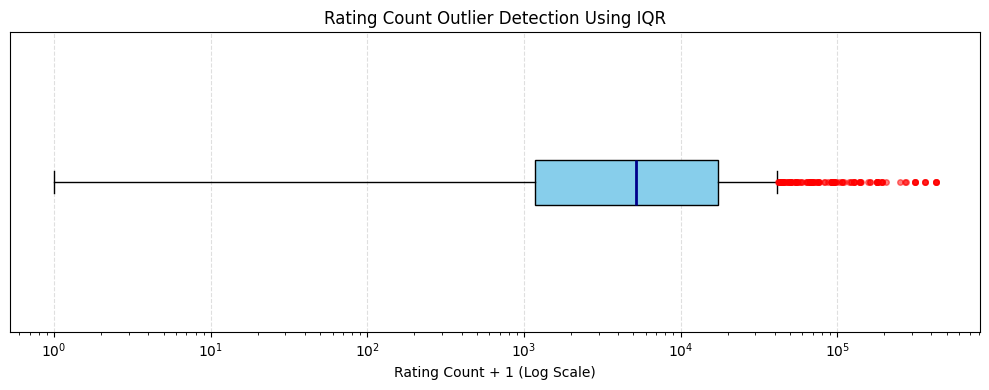

In [26]:
# Member B - Chart 2: Rating Count Outlier Boxplot

import matplotlib.pyplot as plt

# Select valid rating counts
rating_counts = df_quality["rating_count_num"].dropna()

# Create boxplot
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    rating_counts + 1,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="skyblue"),
    medianprops=dict(color="darkblue", linewidth=2),
    flierprops=dict(
        marker="o",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=4,
        alpha=0.5
    )
)

# Use logarithmic scale to display extreme values clearly
ax.set_xscale("log")

ax.set_title("Rating Count Outlier Detection Using IQR")
ax.set_xlabel("Rating Count + 1 (Log Scale)")
ax.set_yticks([])

ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.6 Chart 3: Discounted Price Outlier Boxplot

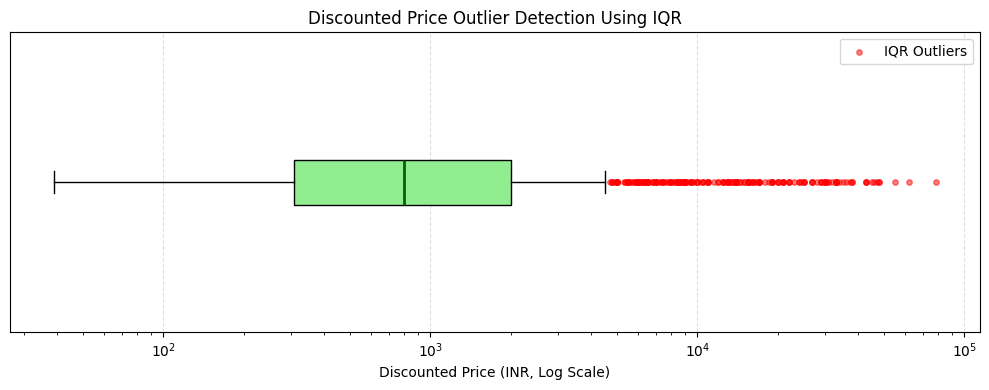

In [27]:
# Member B - Chart 3: Discounted Price Outlier Boxplot

# Select valid positive prices for the log-scale chart
valid_prices = df_quality.loc[
    df_quality["discounted_price_num"] > 0,
    "discounted_price_num"
]

# Select IQR outliers identified earlier
outlier_prices = df_quality.loc[
    df_quality["price_outlier"] &
    (df_quality["discounted_price_num"] > 0),
    "discounted_price_num"
]

# Create boxplot
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    valid_prices,
    vert=False,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor="lightgreen"),
    medianprops=dict(color="darkgreen", linewidth=2)
)

# Highlight the previously detected IQR outliers
ax.scatter(
    outlier_prices,
    np.ones(len(outlier_prices)),
    color="red",
    s=15,
    alpha=0.5,
    label="IQR Outliers"
)

ax.set_xscale("log")

ax.set_title("Discounted Price Outlier Detection Using IQR")
ax.set_xlabel("Discounted Price (INR, Log Scale)")
ax.set_yticks([])

ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.7 Chart 4: Data Quality Issues Bar Chart

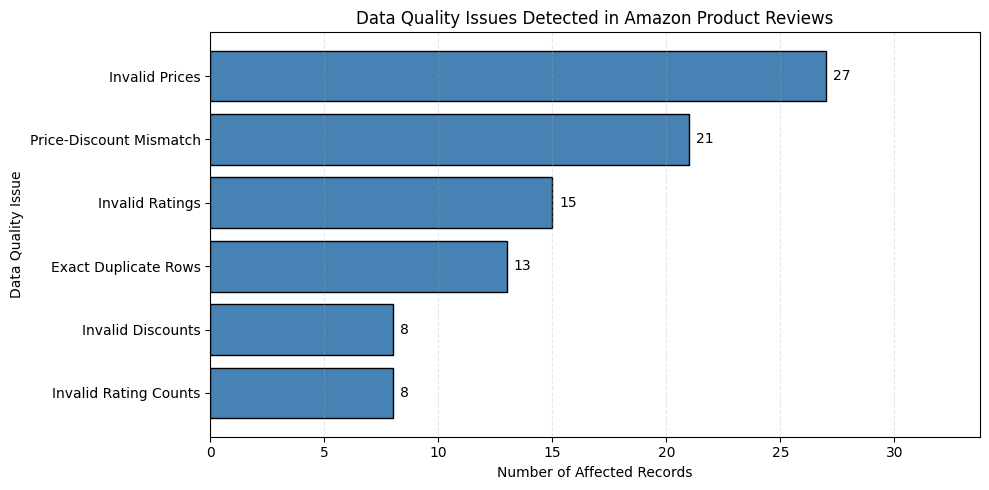

In [28]:
# Member B - Chart 4: Data Quality Issues Bar Chart

# Collect detected data quality issues
issue_counts = pd.Series({
    "Exact Duplicate Rows": int(duplicate_count),
    "Invalid Ratings": int(df_quality["invalid_rating"].sum()),
    "Invalid Rating Counts": int(df_quality["invalid_count"].sum()),
    "Invalid Prices": int(df_quality["invalid_price"].sum()),
    "Invalid Discounts": int(df_quality["invalid_discount"].sum()),
    "Price-Discount Mismatch": int(df_quality["discount_mismatch"].sum())
})

# Sort issues by frequency
issue_counts = issue_counts.sort_values()

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    issue_counts.index,
    issue_counts.values,
    color="steelblue",
    edgecolor="black"
)

# Display values on each bar
ax.bar_label(bars, padding=5)

ax.set_title("Data Quality Issues Detected in Amazon Product Reviews")
ax.set_xlabel("Number of Affected Records")
ax.set_ylabel("Data Quality Issue")

ax.set_xlim(0, issue_counts.max() * 1.25)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.8 Chart 5: Review Content Length Histogram

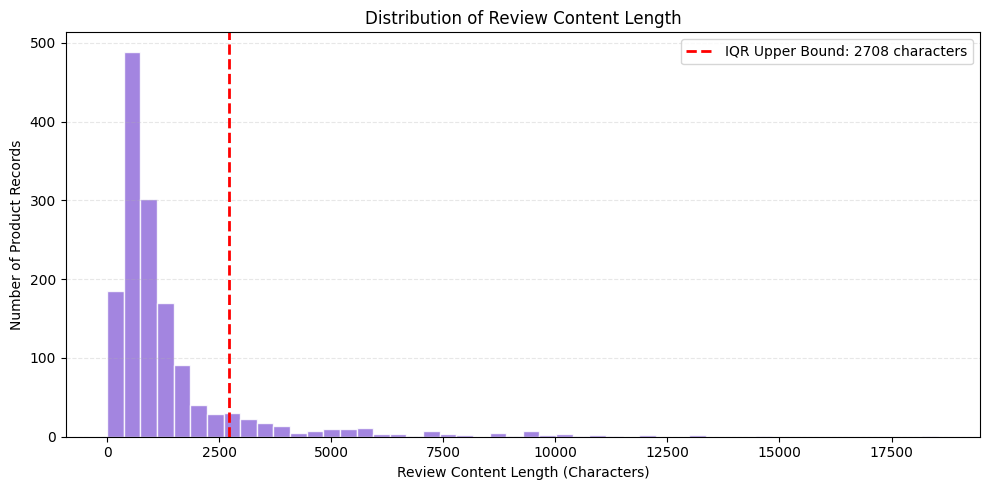

Review length outliers: 171


In [29]:
# Member B - Chart 5: Review Content Length Histogram

# Use review content lengths calculated in Section 3.4
review_lengths = df_quality["review_length"]

# Create histogram
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    review_lengths,
    bins=50,
    color="mediumpurple",
    edgecolor="white",
    alpha=0.85
)

# Mark the IQR upper boundary
ax.axvline(
    text_upper,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"IQR Upper Bound: {text_upper:.0f} characters"
)

ax.set_title("Distribution of Review Content Length")
ax.set_xlabel("Review Content Length (Characters)")
ax.set_ylabel("Number of Product Records")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Show the detected outlier count
print(
    "Review length outliers:",
    df_quality["review_length_outlier"].sum()
)

### 3.9 Data Quality Handling and Justification

In [30]:
# Member B - 3.9 Final Data Quality Handling

# Start from the dataset with exact duplicates removed
df_b_cleaned = df_quality.copy()

# Remove rows with missing or invalid ratings
df_b_cleaned = df_b_cleaned[
    df_b_cleaned["rating_num"].between(1, 5)
].copy()

# Use correctly converted numeric values
df_b_cleaned["rating"] = df_b_cleaned["rating_num"].astype(float)
df_b_cleaned["Rating Count"] = df_b_cleaned["rating_count_num"]

# Fill missing review text
for col in ["review_title", "review_content"]:
    df_b_cleaned[col] = df_b_cleaned[col].fillna(
        "No text provided"
    )

# Fill missing categorical product information
for col in ["product_name", "category"]:
    df_b_cleaned[col] = df_b_cleaned[col].fillna("Unknown")

# Flag questionable price information for later review
df_b_cleaned["needs_price_review"] = (
    df_b_cleaned["invalid_price"] |
    df_b_cleaned["invalid_discount"] |
    df_b_cleaned["discount_mismatch"]
)

# Keep valid statistical outliers for further investigation
# Outlier flags remain in the dataset

print("Original rows:", len(df_raw))
print("Rows after removing exact duplicates:", len(df_quality))

print(
    "Rows excluded due to missing/invalid ratings:",
    len(df_quality) - len(df_b_cleaned)
)

print("Final analysis-ready rows:", len(df_b_cleaned))

print(
    "Rows requiring price review:",
    df_b_cleaned["needs_price_review"].sum()
)

print(
    "Remaining unknown rating counts:",
    df_b_cleaned["Rating Count"].isna().sum()
)

# Validate the cleaned dataset
assert df_b_cleaned["rating"].between(1, 5).all()
assert pd.api.types.is_numeric_dtype(df_b_cleaned["Rating Count"])

print("\nData quality validation completed successfully!")

Original rows: 1495
Rows after removing exact duplicates: 1482
Rows excluded due to missing/invalid ratings: 33
Final analysis-ready rows: 1449
Rows requiring price review: 35
Remaining unknown rating counts: 27

Data quality validation completed successfully!


**1. Duplicate Records (Remove)**

The dataset originally contained 1,495 records, including 13 exact duplicate rows. These duplicates were removed to prevent double-counting during analysis, leaving 1,482 records. Records were only removed when the entire row was duplicated, because repeated product IDs or review IDs do not necessarily indicate identical records.

**2. Invalid and Missing Ratings (Remove)**

Customer ratings are essential for evaluating product satisfaction. Ratings outside the valid range of 1 to 5, as well as missing ratings, cannot be reliably used for this purpose. Therefore, 33 records with missing or invalid ratings were excluded from the satisfaction-analysis dataset, leaving 1,449 records.

**3. Inconsistent Data Types and Formats (Correct)**

Several numerical columns were originally stored as text because of inconsistent formatting. Currency symbols such as ₹ and Rs., thousands separators, and percentage signs were handled during conversion. Rating counts using abbreviations such as "4.4K" were also converted into approximate numerical values.

The original information was preserved for comparison. This ensures that numerical calculations can be performed while maintaining traceability to the source data.

**4. Unknown Rating Counts (Keep as Missing)**

After processing, 27 rating counts remained unknown in the analysis-ready dataset. These values were not replaced with zero or the median because doing so could introduce misleading information about product popularity. They were retained as missing values until more reliable information becomes available.

**5. Invalid Prices and Discount Inconsistencies (Flag)**

The analysis identified invalid prices and inconsistencies between listed prices and discount percentages. In the final analysis-ready dataset, 35 records were flagged for further price review.

These records were not automatically deleted or corrected because the dataset does not provide enough evidence to determine which price or discount value is accurate. The flags allow these records to be excluded from price-dependent calculations until they are verified.

**6. IQR Outliers (Keep and Flag)**

The Interquartile Range (IQR) method was used to detect potential outliers using the 1.5 × IQR rule.

In the deduplicated dataset, the analysis identified:

139 outliers in Rating Count.

217 outliers in Discounted Price.

171 outliers in Review Content Length.

These outliers were retained because extreme values are not necessarily data errors. Products may legitimately receive unusually large numbers of ratings or have high prices. Furthermore, review-content fields may contain multiple reviews associated with one product, which can explain unusually long text.

The outlier flags were preserved for further investigation rather than removing potentially valid information.

**7. Missing Text and Categorical Values (Impute)**

Missing review titles and review content were replaced with "No text provided" to preserve records with otherwise valid ratings. Missing product names and categories were filled with "Unknown".

These placeholders clearly indicate unavailable information without inventing customer feedback or product details. Records containing placeholder review text should not be treated as genuine customer statements during sentiment analysis.